In [18]:
import os
import pandas as pd
from datetime import datetime
import glob
import unicodedata
import re
import numpy as np
#import ace_tools as tools
import matplotlib.pyplot as plt
import calendar
import seaborn as sns

In [19]:
os.makedirs('data_2025_2026', exist_ok=True)

def extract_bronze_layer(data_dir: str) -> pd.DataFrame:
    """
    Lee dinámicamente todos los csv de un directorio, los concatena (une)
    y añade metadatos de auditoría para la capa Bronze.
    """

    csv_files = glob.glob(os.path.join(data_dir, '*.csv'))

    if not csv_files:
        raise FileNotFoundError(f"No se encontraron archivos CSV en el directorio '{data_dir}'")
    df_list = []

    #timestamp unificado para todo el lote de ingesta
    ingestion_timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    for file_path in csv_files:
        try:
            # dtype=str garantiza que no haya pérdida de precisión
            df = pd.read_csv(file_path, sep=';', dtype=str, encoding='utf-8')

            #Metadatos de auditoría
            df['_source_filename'] = os.path.basename(file_path)
            df['_ingestion_timestamp'] = ingestion_timestamp

            df_list.append(df)
            print(f"Ingesta exitosa: {os.path.basename(file_path)} | Registros: {len(df)}")
        except Exception as e:
            print(f"Error crítico al leer {file_path}: {str(e)}")

    #Concatenación final
    bronze_df = pd.concat(df_list, ignore_index=True)
    return bronze_df


In [20]:
if __name__ == "__main__":
    # Ruta a la carpeta de datos
    CARPETA_DATOS = "./data_2025_2026"
    
    try:
        # Ejecutar extracción
        df_bronze = extract_bronze_layer(CARPETA_DATOS)
        
        # Validar resultados en consola
        print("\nExtracción completada con éxito.")
        print(f"Total de registros ingestados: {len(df_bronze)}")
        print("\nMuestra de los datos (Capa Bronze):")
        print(df_bronze[['Carrier Name', 'Dest', 'Origin', '_source_filename', '_ingestion_timestamp']].head())
        
        # Opcional: Guardar el resultado consolidado para consumo de la capa Silver
        # df_bronze.to_parquet("bronze_layer.parquet", index=False)
        
    except Exception as e:
        print(f"Fallo en el pipeline de ingesta: {e}")

Ingesta exitosa: 2025-01-panama-to-usa.csv | Registros: 50
Ingesta exitosa: 2025-01-usa-to-panama.csv | Registros: 52
Ingesta exitosa: 2025-02-panama-to-usa.csv | Registros: 44
Ingesta exitosa: 2025-02-usa-to-panama.csv | Registros: 49
Ingesta exitosa: 2025-03-panama-to-usa.csv | Registros: 42
Ingesta exitosa: 2025-03-usa-to-panama.csv | Registros: 50
Ingesta exitosa: 2025-04-panama-to-usa.csv | Registros: 45
Ingesta exitosa: 2025-04-usa-to-panama.csv | Registros: 49
Ingesta exitosa: 2025-05-panama-to-usa.csv | Registros: 48
Ingesta exitosa: 2025-05-usa-to-panama.csv | Registros: 53
Ingesta exitosa: 2025-06-panama-to-usa.csv | Registros: 52
Ingesta exitosa: 2025-06-usa-to-panama.csv | Registros: 54
Ingesta exitosa: 2025-07-panama-to-usa.csv | Registros: 59
Ingesta exitosa: 2025-07-usa-to-panama.csv | Registros: 55
Ingesta exitosa: 2025-08-panama-to-usa.csv | Registros: 48
Ingesta exitosa: 2025-08-usa-to-panama.csv | Registros: 53
Ingesta exitosa: 2025-09-panama-to-usa.csv | Registros: 

In [21]:
#bronze_df
df_bronze.to_csv('bronze_layer_output.csv', index=False)

In [22]:
df_bronze.head(2)

,Carrier Name,Dest,Origin,PlaneDirection_EW 1,Dest City Name,Dest Country Name,Month,Origin City Name,Origin Country Name,Year,Latitud (generado),Longitud (generado),Máx. Distance,DestPoint,RouteLine,Select Measure_Freight,_source_filename,_ingestion_timestamp
0,United Air Lines Inc.,MFE,PTY,NaN,"Mission/McAllen/Edinburg, TX",United States,January,"Panama City, Panama",Panama,2025,"17,849162720","-88,356490777",1707,NaN,LineString,0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22
1,United Air Lines Inc.,IAH,PTY,NaN,"Houston, TX",United States,January,"Panama City, Panama",Panama,2025,"19,703413282","-86,836703266",1771,NaN,LineString,192125,2025-01-panama-to-usa.csv,2026-10-24 07:56:22


In [23]:
df_bronze['Select Measure_Freight'] = pd.to_numeric(
    df_bronze['Select Measure_Freight'], errors='coerce'
).fillna(0)


In [24]:
df_grouped = (
    df_bronze.groupby(['Year', 'Origin', 'Dest'], as_index=False)[
        'Select Measure_Freight'
    ]
    .sum()
    .rename(columns={'Dest': 'Destination'})
)
df_grouped.head()

,Year,Origin,Destination,Select Measure_Freight
0,2025,AEX,PTY,0.0
1,2025,AFW,HOW,0.0
2,2025,ATL,PTY,272640.0
3,2025,AUS,PTY,6303.0
4,2025,BOS,PTY,1797.0


In [25]:
df_airport = pd.read_csv(
    'GlobalAirportDatabase.txt',
    sep=":",
    header=None,
    usecols=[1, 14,15],
    names=["iata_code", 'lat', 'long'],
    dtype={"iata_code": str, "lat": float, "long": float},
)
df_airport_clean = df_airport[~((df_airport["lat"] == 0.0) & (df_airport["long"] == 0.0))].reset_index(drop=True)
df_airport_clean.head(2)


,iata_code,lat,long
0,GKA,-6.082,145.392
1,MAG,-5.207,145.789


In [26]:
df_merged = df_grouped.merge(
    df_airport_clean[['iata_code', 'lat', 'long']],
    left_on='Origin',
    right_on='iata_code',
    how='left'
).rename(columns={'lat': 'origin_lat', 'long': 'origin_long'}).drop(columns=['iata_code'])

df_final = df_merged.merge(
    df_airport_clean[['iata_code', 'lat', 'long']],
    left_on='Destination',
    right_on='iata_code',
    how='left'
    ).rename(columns={'lat': 'dest_lat', 'long': 'dest_long'}).drop(columns=['iata_code'])
df_final = df_final[~((df_final["Select Measure_Freight"] == 0.0))].reset_index(drop=True)
df_final[df_final['Year']=='2025'].head()
df_final[df_final['Year']=='2025'].to_csv('bronze_visualization.csv', index=False)

In [27]:
df_bronze['Select Measure_Freight'] = pd.to_numeric(
    df_bronze['Select Measure_Freight'], errors='coerce'
).fillna(0)
df_2025 = df_bronze[df_bronze['Year'] == '2025'].copy()


In [28]:
df_2025.head(1)

,Carrier Name,Dest,Origin,PlaneDirection_EW 1,Dest City Name,Dest Country Name,Month,Origin City Name,Origin Country Name,Year,Latitud (generado),Longitud (generado),Máx. Distance,DestPoint,RouteLine,Select Measure_Freight,_source_filename,_ingestion_timestamp
0,United Air Lines Inc.,MFE,PTY,NaN,"Mission/McAllen/Edinburg, TX",United States,January,"Panama City, Panama",Panama,2025,"17,849162720","-88,356490777",1707,NaN,LineString,0.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22


In [29]:
df_bronze.head(1)

,Carrier Name,Dest,Origin,PlaneDirection_EW 1,Dest City Name,Dest Country Name,Month,Origin City Name,Origin Country Name,Year,Latitud (generado),Longitud (generado),Máx. Distance,DestPoint,RouteLine,Select Measure_Freight,_source_filename,_ingestion_timestamp
0,United Air Lines Inc.,MFE,PTY,NaN,"Mission/McAllen/Edinburg, TX",United States,January,"Panama City, Panama",Panama,2025,"17,849162720","-88,356490777",1707,NaN,LineString,0.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22


In [30]:
df_2025.head(2)

,Carrier Name,Dest,Origin,PlaneDirection_EW 1,Dest City Name,Dest Country Name,Month,Origin City Name,Origin Country Name,Year,Latitud (generado),Longitud (generado),Máx. Distance,DestPoint,RouteLine,Select Measure_Freight,_source_filename,_ingestion_timestamp
0,United Air Lines Inc.,MFE,PTY,NaN,"Mission/McAllen/Edinburg, TX",United States,January,"Panama City, Panama",Panama,2025,"17,849162720","-88,356490777",1707,NaN,LineString,0.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22
1,United Air Lines Inc.,IAH,PTY,NaN,"Houston, TX",United States,January,"Panama City, Panama",Panama,2025,"19,703413282","-86,836703266",1771,NaN,LineString,192125.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22


In [31]:
conditions = [
    (df_2025['Dest'] == 'PTY') & (df_2025['Origin'] != 'PTY'),
    (df_2025['Origin'] == 'PTY') & (df_2025['Dest'] != 'PTY'),
]

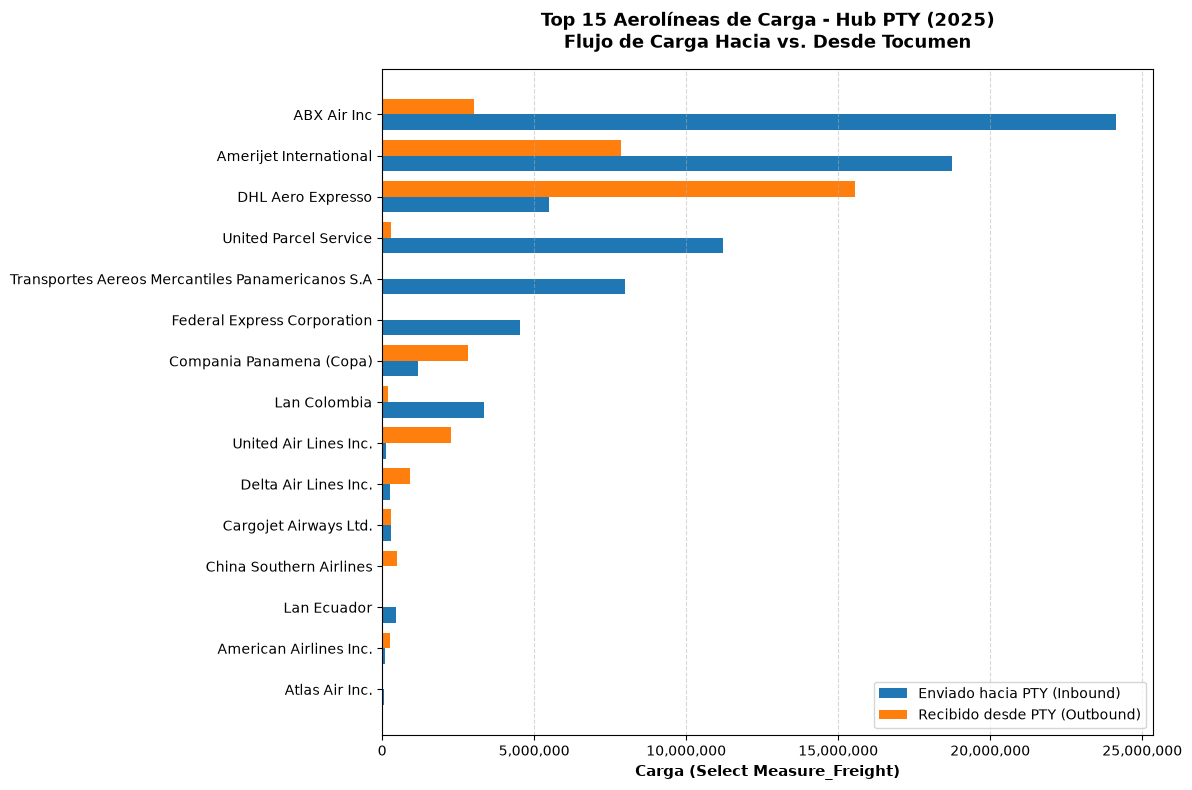

In [32]:
choices = ['Hacia PTY (Enviado a PTY)', 'Desde PTY (Recibido de PTY)']
df_2025['Flujo'] = np.select(conditions, choices, default='Otros')

# Filtrar únicamente operaciones que involucran a PTY
df_pty = df_2025[df_2025['Flujo'].isin(choices)]

# 3. Tabla pivote por Carrier y Flujo
pivot = df_pty.pivot_table(
    index='Carrier Name',
    columns='Flujo',
    values='Select Measure_Freight',
    aggfunc='sum',
    fill_value=0,
)

# Garantizar ambas columnas aunque no existan en una muestra pequeña
for col in choices:
    if col not in pivot.columns:
        pivot[col] = 0

# 4. Seleccionar Top 15 aerolíneas por volumen global
pivot['Total'] = pivot.sum(axis=1)
top15 = pivot.sort_values(by='Total', ascending=True).tail(15)  # Ascendente para barra horizontal
top15_plot = top15[choices]

# 5. Visualización con Matplotlib
fig, ax = plt.subplots(figsize=(12, 8), dpi=100)

y_positions = np.arange(len(top15_plot))
bar_height = 0.38

rects1 = ax.barh(
    y_positions - bar_height / 2,
    top15_plot['Hacia PTY (Enviado a PTY)'],
    height=bar_height,
    label='Enviado hacia PTY (Inbound)',
    color='#1f77b4',
)
rects2 = ax.barh(
    y_positions + bar_height / 2,
    top15_plot['Desde PTY (Recibido de PTY)'],
    height=bar_height,
    label='Recibido desde PTY (Outbound)',
    color='#ff7f0e',
)

# Etiquetas y formato
ax.set_yticks(y_positions)
ax.set_yticklabels(top15_plot.index, fontsize=10)
ax.set_xlabel('Carga (Select Measure_Freight)', fontsize=11, fontweight='bold')
ax.set_title(
    'Top 15 Aerolíneas de Carga - Hub PTY (2025)\nFlujo de Carga Hacia vs. Desde Tocumen',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.legend(frameon=True, facecolor='white', loc='lower right')
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'{int(x):,}')
)
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

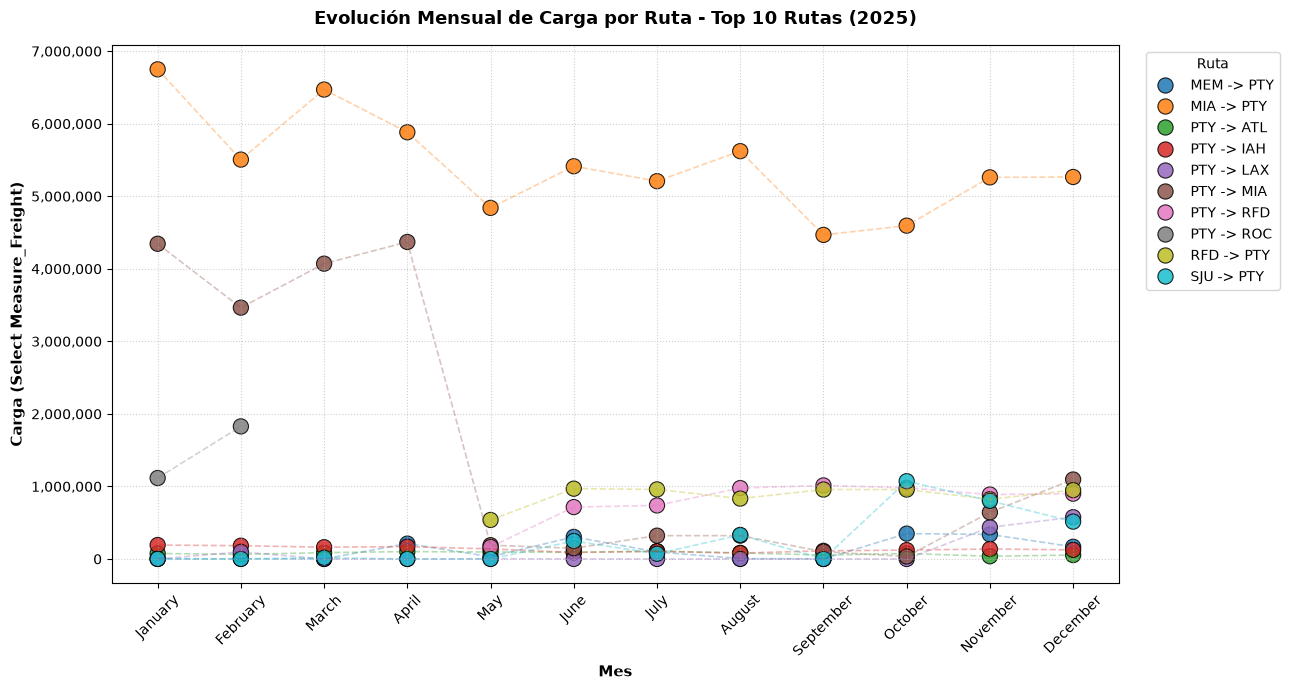

In [33]:
# Limpieza 
df = df_2025.copy()
df['Origin'] = df['Origin'].astype(str).str.strip().str.upper()
df['Dest'] = df['Dest'].astype(str).str.strip().str.upper()
df['Month'] = df['Month'].astype(str).str.strip().str.capitalize()
df['Select Measure_Freight'] = pd.to_numeric(
    df['Select Measure_Freight'], errors='coerce'
).fillna(0)
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')

# Construir ruta
df['Route'] = df['Origin'] + ' -> ' + df['Dest']

# 3. Filtrar año y ordenar meses cronológicamente
df_target = df[df['Year'] == 2025].copy()

month_order = [calendar.month_name[i] for i in range(1, 13)]
df_target['Month'] = pd.Categorical(
    df_target['Month'], categories=month_order, ordered=True
)

# 4. Agrupar totales por Ruta y Mes
df_monthly_routes = (
    df_target.groupby(['Route', 'Month'], observed=True)[
        'Select Measure_Freight'
    ]
    .sum()
    .reset_index()
)

# 5. Seleccionar Top 10 rutas por volumen total acumulado
top_routes = (
    df_monthly_routes.groupby('Route')['Select Measure_Freight']
    .sum()
    .nlargest(10)
    .index.tolist()
)

df_plot = df_monthly_routes[df_monthly_routes['Route'].isin(top_routes)].copy()

# 6. Scatter Plot
plt.figure(figsize=(13, 7), dpi=100)
palette = sns.color_palette('tab10', n_colors=len(top_routes))

scatter = sns.scatterplot(
    data=df_plot,
    x='Month',
    y='Select Measure_Freight',
    hue='Route',
    palette=palette,
    s=120,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.8,
)

# Opcional: línea tenue conectando la evolución de cada ruta
sns.lineplot(
    data=df_plot,
    x='Month',
    y='Select Measure_Freight',
    hue='Route',
    palette=palette,
    legend=False,
    alpha=0.35,
    linestyle='--',
    linewidth=1.2,
)

# Formato visual
plt.title(
    'Evolución Mensual de Carga por Ruta - Top 10 Rutas (2025)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Mes', fontsize=11, fontweight='bold')
plt.ylabel('Carga (Select Measure_Freight)', fontsize=11, fontweight='bold')
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, p: f'{int(x):,}')
)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45)

# Leyenda fuera del gráfico para evitar oclusión
plt.legend(
    title='Ruta',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    facecolor='white',
)

plt.tight_layout()
plt.show()

In [34]:
df_plot.to_csv('df_flot.csv', index=False)

In [35]:
top15.tail()

Flujo,Desde PTY (Recibido de PTY),Hacia PTY (Enviado a PTY),Total
Carrier Name,,,
Transportes Aereos Mercantiles Panamericanos S.A,0.0,7975854.0,7975854.0
United Parcel Service,279032.0,11214654.0,11493686.0
DHL Aero Expresso,15550848.0,5471469.0,21022317.0
Amerijet International,7867234.0,18750304.0,26617538.0
ABX Air Inc,3015628.0,24150482.0,27166110.0


In [36]:
def clean_column_names(columns: list) -> list:
    """
    Estandariza los nombres de las columnas a formato snake_case.
    """
    clean_cols = []
    for col in columns:
        # remover acentos
        col = ''.join(c for c in unicodedata.normalize('NFD', col) if unicodedata.category(c) != 'Mn')
        # Reemplazar caracteres especiales y espacios por guiones bajos
        col = re.sub(r'[^a-zA-Z0-9]+', '_', col)
        # Convertir a minúsculas y eliminar guiones bajos en los extremos
        clean_cols.append(col.lower().strip('_'))

    return clean_cols


def transform_silver_layer(bronze_df: pd.DataFrame) -> pd.DataFrame:
    """
    Aplica las transformaciones de limpieza (Capa silver).
    """
    df = bronze_df.copy()
    df.columns = clean_column_names(df.columns)

    # Ajuste manual para planedirection
    df = df.rename(columns={
        'planedirection_ew_1': 'plane_direction_ew_1',
        'destpoint': 'dest_point',
        'routeline': 'route_line'
    })

    df['latitud_generado'] = df['latitud_generado'].astype(str).str.replace(',', '.').astype(float)
    df['longitud_generado'] = df['longitud_generado'].astype(str).str.replace(',', '.').astype(float)

    # 3. Tratamiento de nulos o vacíos
    df['plane_direction_ew_1'] = df['plane_direction_ew_1'].fillna('Unknown')
    df['dest_point'] = df['dest_point'].fillna('Unknown')

    # 4. Casteo de métricas de negocio
    df['select_measure_freight'] = pd.to_numeric(df['select_measure_freight'], errors='coerce').fillna(0).astype(int)
    df['max_distance'] = pd.to_numeric(df['max_distance'], errors='coerce').fillna(0).astype(float)

    # 5. Estandarización temporal
    df['year'] = pd.to_numeric(df['year'], errors='coerce').fillna(1900).astype(int)
    df['month'] = df['month'].astype(str).str.strip().str.capitalize()

    # 6. Metadatos
    df['_silver_transformation_timestamp'] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    return df

# Ejecutar y guardar
df_silver = transform_silver_layer(df_bronze)
df_silver.to_csv('silver_layer_output.csv', index=False)

df_silver.head()



,carrier_name,dest,origin,plane_direction_ew_1,dest_city_name,dest_country_name,month,origin_city_name,origin_country_name,year,latitud_generado,longitud_generado,max_distance,dest_point,route_line,select_measure_freight,source_filename,ingestion_timestamp,_silver_transformation_timestamp
0,United Air Lines Inc.,MFE,PTY,Unknown,"Mission/McAllen/Edinburg, TX",United States,January,"Panama City, Panama",Panama,2025,17.849163,-88.356491,1707.0,Unknown,LineString,0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22,2026-10-24 07:56:23
1,United Air Lines Inc.,IAH,PTY,Unknown,"Houston, TX",United States,January,"Panama City, Panama",Panama,2025,19.703413,-86.836703,1771.0,Unknown,LineString,192125,2025-01-panama-to-usa.csv,2026-10-24 07:56:22,2026-10-24 07:56:23
2,United Air Lines Inc.,EWR,PTY,Unknown,"Newark, NJ",United States,January,"Panama City, Panama",Panama,2025,24.904213,-77.118642,2200.0,Unknown,LineString,31815,2025-01-panama-to-usa.csv,2026-10-24 07:56:22,2026-10-24 07:56:23
3,United Air Lines Inc.,AUS,PTY,Unknown,"Austin, TX",United States,January,"Panama City, Panama",Panama,2025,19.864877,-87.913328,1873.0,Unknown,LineString,0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22,2026-10-24 07:56:23
4,"Global Crossing Airlines, Inc.",AEX,PTY,Unknown,"Alexandria, LA",United States,January,"Panama City, Panama",Panama,2025,20.321909,-85.487493,1750.0,Unknown,LineString,0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22,2026-10-24 07:56:23


In [37]:
df_bronze.head()

,Carrier Name,Dest,Origin,PlaneDirection_EW 1,Dest City Name,Dest Country Name,Month,Origin City Name,Origin Country Name,Year,Latitud (generado),Longitud (generado),Máx. Distance,DestPoint,RouteLine,Select Measure_Freight,_source_filename,_ingestion_timestamp
0,United Air Lines Inc.,MFE,PTY,NaN,"Mission/McAllen/Edinburg, TX",United States,January,"Panama City, Panama",Panama,2025,"17,849162720","-88,356490777",1707,NaN,LineString,0.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22
1,United Air Lines Inc.,IAH,PTY,NaN,"Houston, TX",United States,January,"Panama City, Panama",Panama,2025,"19,703413282","-86,836703266",1771,NaN,LineString,192125.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22
2,United Air Lines Inc.,EWR,PTY,NaN,"Newark, NJ",United States,January,"Panama City, Panama",Panama,2025,"24,904213115","-77,118642278",2200,NaN,LineString,31815.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22
3,United Air Lines Inc.,AUS,PTY,NaN,"Austin, TX",United States,January,"Panama City, Panama",Panama,2025,"19,864876959","-87,913327834",1873,NaN,LineString,0.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22
4,"Global Crossing Airlines, Inc.",AEX,PTY,NaN,"Alexandria, LA",United States,January,"Panama City, Panama",Panama,2025,"20,321909495","-85,487493159",1750,NaN,LineString,0.0,2025-01-panama-to-usa.csv,2026-10-24 07:56:22


In [38]:
print(df_silver.dtypes)

carrier_name                            str
dest                                    str
origin                                  str
plane_direction_ew_1                    str
dest_city_name                          str
dest_country_name                       str
month                                   str
origin_city_name                        str
origin_country_name                     str
year                                  int64
latitud_generado                    float64
longitud_generado                   float64
max_distance                        float64
dest_point                              str
route_line                              str
select_measure_freight                int64
source_filename                         str
ingestion_timestamp                     str
_silver_transformation_timestamp        str
dtype: object


C:\Users\PC-2025-08-01\AppData\Local\Temp\ipykernel_16004\3992036582.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\PC-2025-08-01\AppData\Local\Temp\ipykernel_16004\3992036582.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


Dashboard guardado como 'dashboard_capa_gold.png'

Pipeline Capa Gold finalizado.
Tablas agregadas creadas exitosamente para explotación.


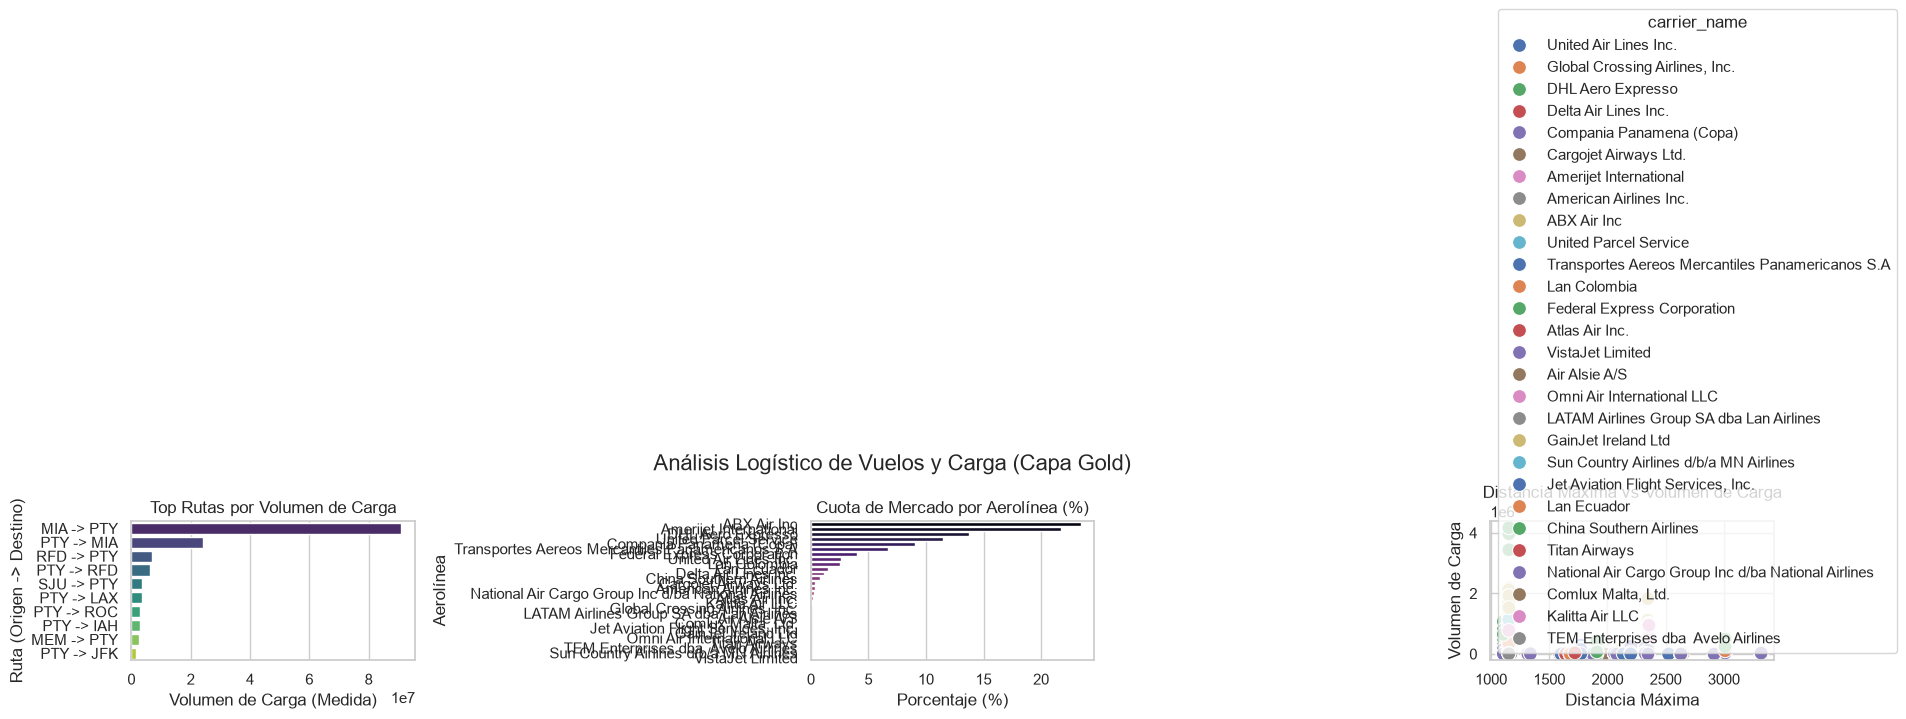

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

def generate_gold_layer(silver_file_path: str):
    """
    Genera agregaciones de negocio y visualizaciones para la Capa Gold.
    """
    # 1. Ingesta de la Capa Silver
    df = pd.read_csv(silver_file_path)
    
    # --- CREACIÓN DE DATA MARTS DE NEGOCIO ---
    # Data Mart: Volumen por Ruta
    df_routes = df.groupby(['origin', 'dest', 'origin_city_name', 'dest_city_name'])['select_measure_freight'].sum().reset_index()
    df_routes['route'] = df_routes['origin'] + ' -> ' + df_routes['dest']
    df_routes = df_routes.sort_values(by='select_measure_freight', ascending=False)
    
    # Data Mart: Market Share de Aerolíneas
    df_carrier = df.groupby('carrier_name')['select_measure_freight'].sum().reset_index()
    df_carrier['market_share_pct'] = (df_carrier['select_measure_freight'] / df_carrier['select_measure_freight'].sum()) * 100
    df_carrier = df_carrier.sort_values(by='market_share_pct', ascending=False)
    
    # --- VISUALIZACIÓN ANALÍTICA (EDA)
    
    # Configurar estilo visual
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Análisis Logístico de Vuelos y Carga (Capa Gold)', fontsize=16)

    # Gráfico 1: Top 10 Rutas por Carga
    sns.barplot(
        data=df_routes.head(10), 
        x='select_measure_freight', 
        y='route', 
        ax=axes[0], 
        palette='viridis'
    )
    axes[0].set_title('Top Rutas por Volumen de Carga')
    axes[0].set_xlabel('Volumen de Carga (Medida)')
    axes[0].set_ylabel('Ruta (Origen -> Destino)')

    # Gráfico 2: Market Share
    sns.barplot(
        data=df_carrier, 
        x='market_share_pct', 
        y='carrier_name', 
        ax=axes[1], 
        palette='magma'
    )
    axes[1].set_title('Cuota de Mercado por Aerolínea (%)')
    axes[1].set_xlabel('Porcentaje (%)')
    axes[1].set_ylabel('Aerolínea')

    # Gráfico 3: Correlación Distancia vs Carga
    sns.scatterplot(
        data=df, 
        x='max_distance', 
        y='select_measure_freight', 
        hue='carrier_name', 
        s=100, 
        ax=axes[2], 
        palette='deep'
    )
    axes[2].set_title('Distancia Máxima vs Volumen de Carga')
    axes[2].set_xlabel('Distancia Máxima')
    axes[2].set_ylabel('Volumen de Carga')

    # Ajustar layout y guardar el artefacto
    plt.tight_layout()
    plt.savefig('dashboard_capa_gold.png', dpi=300)
    print("Dashboard guardado como 'dashboard_capa_gold.png'")
    
    # Exportar Data Marts (Listos para PowerBI o SQL)
    df_routes.to_csv('gold_mart_routes.csv', index=False)
    df_carrier.to_csv('gold_mart_market_share.csv', index=False)
    
    return df_routes, df_carrier

if __name__ == "__main__":
    try:
        df_routes_gold, df_market_share = generate_gold_layer('silver_layer_output.csv')
        print("\nPipeline Capa Gold finalizado.")
        print("Tablas agregadas creadas exitosamente para explotación.")
    except Exception as e:
        print(f"Error procesando la capa Gold: {e}")

In [40]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [41]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
